In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/package_deliveries.csv")

In [2]:
df.head()

,package_id,distance_km,package_weight,package_size,traffic_level,weather,hour_of_day,day_of_week,pending_orders,warehouse_processing_minutes,promised_delivery_minutes,delivery_time_minutes,delayed
0,SF0001,11.86,13.52,Medium,High,Cloudy,19,Sunday,15,5,66.51,72.02,1
1,SF0002,28.57,15.97,Small,Medium,Clear,13,Thursday,28,15,135.00,133.03,0
2,SF0003,22.23,5.16,Large,Medium,Clear,20,Saturday,0,10,107.80,84.57,0
3,SF0004,18.36,12.57,Medium,Medium,Cloudy,20,Wednesday,17,27,111.26,116.20,1
4,SF0005,5.52,11.52,Small,Medium,Cloudy,11,Monday,21,13,52.32,43.28,0


In [3]:
df.shape


(3000, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   package_id                    3000 non-null   object 
 1   distance_km                   3000 non-null   float64
 2   package_weight                3000 non-null   float64
 3   package_size                  3000 non-null   object 
 4   traffic_level                 3000 non-null   object 
 5   weather                       3000 non-null   object 
 6   hour_of_day                   3000 non-null   int64  
 7   day_of_week                   3000 non-null   object 
 8   pending_orders                3000 non-null   int64  
 9   warehouse_processing_minutes  3000 non-null   int64  
 10  promised_delivery_minutes     3000 non-null   float64
 11  delivery_time_minutes         3000 non-null   float64
 12  delayed                       3000 non-null   int64  
dtypes: 

In [5]:
df.describe()

,distance_km,package_weight,hour_of_day,pending_orders,warehouse_processing_minutes,promised_delivery_minutes,delivery_time_minutes,delayed
count,3000.000000,3000.000000,3000.00000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000
mean,15.496937,9.987460,14.37400,24.86000,17.349667,91.588967,95.538047,0.612667
std,8.458077,5.690933,3.99284,14.64331,7.464537,30.540284,33.659592,0.487222
min,1.000000,0.200000,8.00000,0.00000,5.000000,28.960000,10.000000,0.000000
25%,8.127500,5.067500,11.00000,12.00000,11.000000,65.937500,69.180000,0.000000
50%,15.655000,9.865000,14.00000,25.00000,17.000000,92.165000,95.735000,1.000000
75%,22.872500,14.822500,18.00000,37.00000,24.000000,116.780000,122.317500,1.000000
max,29.990000,19.990000,21.00000,50.00000,30.000000,154.620000,181.080000,1.000000


In [6]:
df.isnull().sum()

package_id                      0
distance_km                     0
package_weight                  0
package_size                    0
traffic_level                   0
weather                         0
hour_of_day                     0
day_of_week                     0
pending_orders                  0
warehouse_processing_minutes    0
promised_delivery_minutes       0
delivery_time_minutes           0
delayed                         0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
print(df["traffic_level"].value_counts())

print(df["weather"].value_counts())

print(df["package_size"].value_counts())

print(df["delayed"].value_counts())

traffic_level
Medium    1348
Low        883
High       769
Name: count, dtype: int64
weather
Clear     1518
Cloudy     876
Rainy      606
Name: count, dtype: int64
package_size
Small     1561
Medium     866
Large      573
Name: count, dtype: int64
delayed
1    1838
0    1162
Name: count, dtype: int64


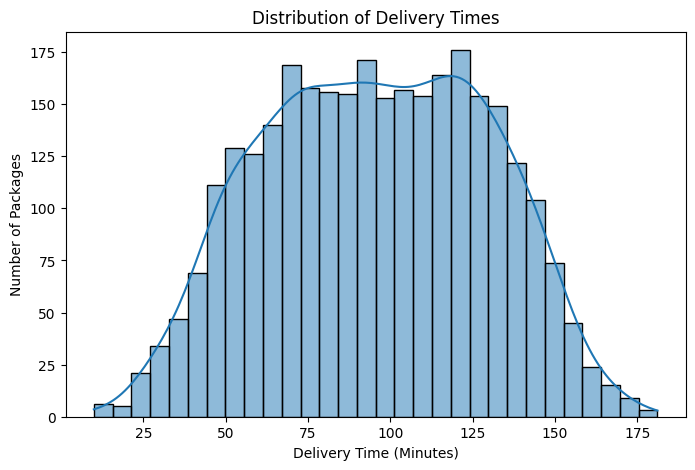

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["delivery_time_minutes"],
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Times")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Packages")

plt.show()

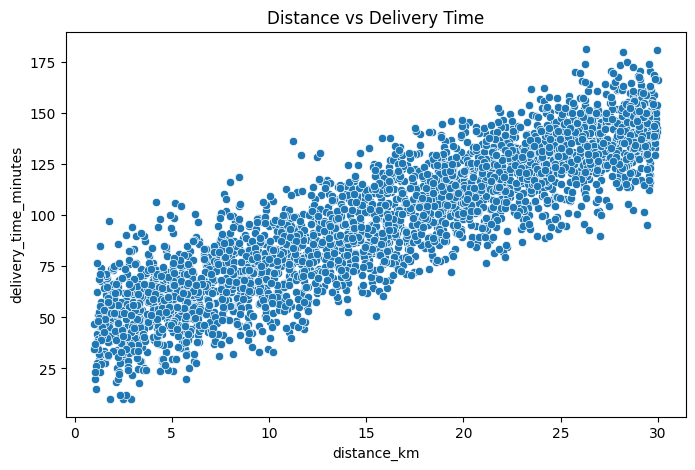

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="distance_km",
    y="delivery_time_minutes"
)

plt.title("Distance vs Delivery Time")
plt.show()

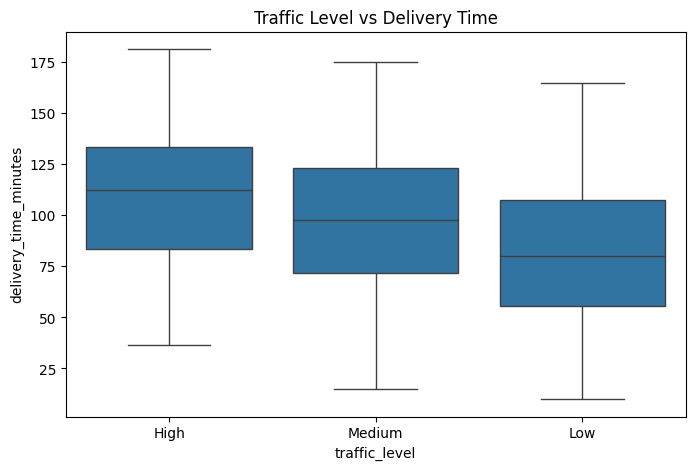

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="traffic_level",
    y="delivery_time_minutes"
)

plt.title("Traffic Level vs Delivery Time")
plt.show()

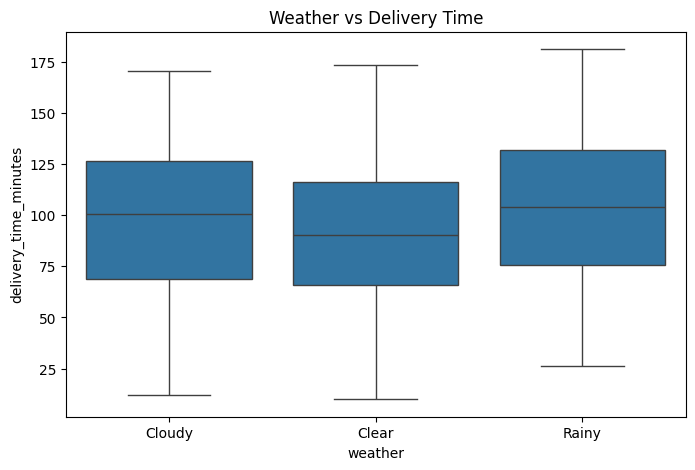

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="weather",
    y="delivery_time_minutes"
)

plt.title("Weather vs Delivery Time")
plt.show()

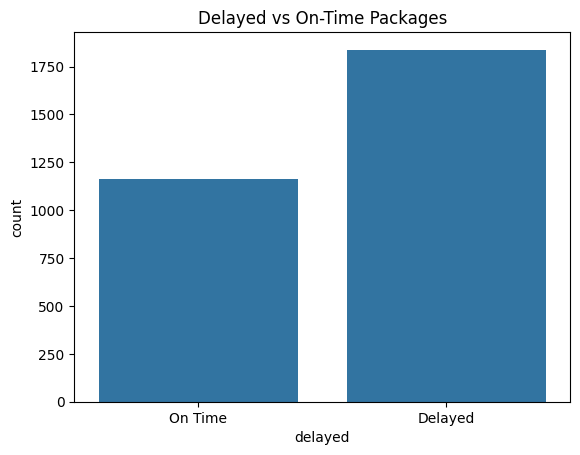

In [13]:
sns.countplot(
    data=df,
    x="delayed"
)

plt.title("Delayed vs On-Time Packages")
plt.xticks([0, 1], ["On Time", "Delayed"])

plt.show()

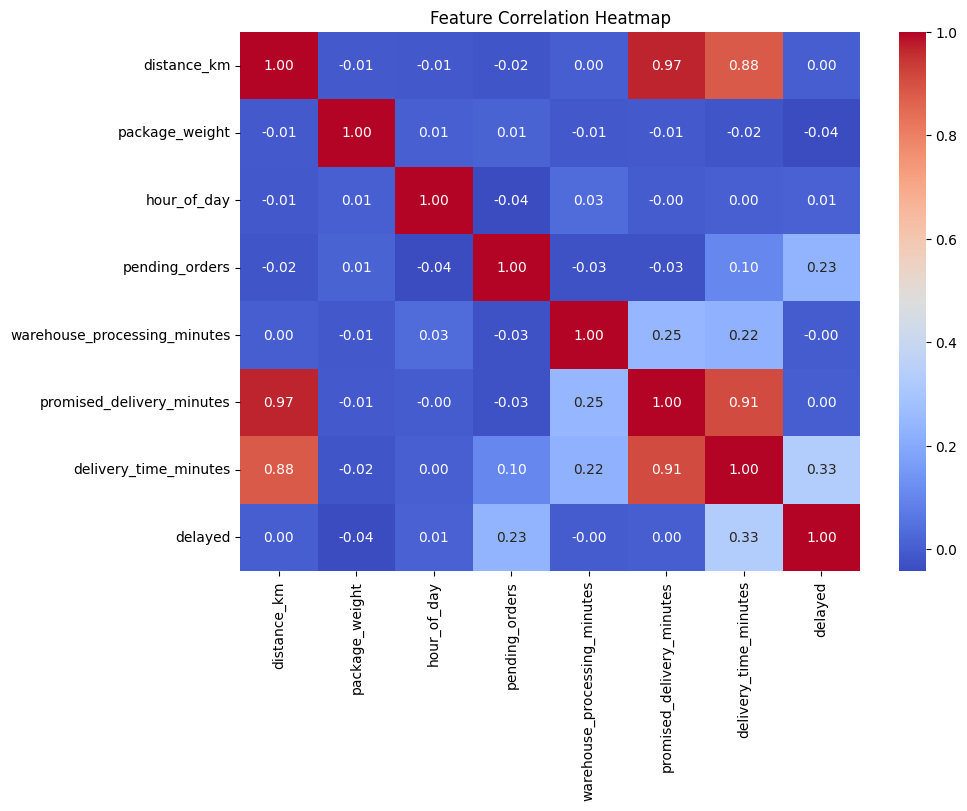

In [14]:
numerical_df = df.select_dtypes(
    include=["number"]
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

## EDA Findings

1. Delivery time generally increases with distance.
2. High traffic is associated with longer delivery times.
3. Rainy weather shows higher delivery durations
   than clear weather in the simulated data.
4. Package weight has a weaker relationship with
   delivery time in the generated dataset.
5. Delivery delay is represented as a binary target.